In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from tensorflow import keras
import tensorflow as tf
from pathlib import Path
import random
import glob
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocessing 
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocessing
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenetv2_preprocessing 
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [ ]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
        tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)

Epoch 1/4
 4/60 ━━━━━━━━━━━━━━━━━━━━ 2:45 3s/step - accuracy: 0.3815 - f1: 0.3116 - loss: 4.6491 - pr_auc: 0.4434 - precision: 0.3370 - recall: 0.3518 - roc_auc: 0.4127

In [ ]:
model.save("../models/custom_model.keras")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

73825

In [7]:
print(train_dataset.class_names)

['flip', 'notflip']


In [43]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

NameError: name 'history' is not defined

In [7]:
resnet50_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
resnet50_base_model.trainable = False

resnet50_model = Sequential()
resnet50_model.add(Input(shape=(224, 224, 3)))
resnet50_model.add(tf.keras.layers.Lambda(resnet50_preprocessing))
resnet50_model.add(resnet50_base_model)
resnet50_model.add(GlobalAveragePooling2D())
resnet50_model.add(Dense(1, activation="sigmoid"))

resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

resnet50_model_history = resnet50_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 330s 5s/step - accuracy: 0.7837 - f1: 0.7922 - loss: 0.4845 - pr_auc: 0.8446 - precision: 0.7789 - recall: 0.8059 - roc_auc: 0.8591 - val_accuracy: 0.8933 - val_f1: 0.9054 - val_loss: 0.3382 - val_pr_auc: 0.9738 - val_precision: 0.8472 - val_recall: 0.9721 - val_roc_auc: 0.9720
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 306s 5s/step - accuracy: 0.9248 - f1: 0.9286 - loss: 0.2654 - pr_auc: 0.9791 - precision: 0.9018 - recall: 0.9571 - roc_auc: 0.9784 - val_accuracy: 0.9226 - val_f1: 0.9218 - val_loss: 0.2579 - val_pr_auc: 0.9913 - val_precision: 0.9820 - val_recall: 0.8685 - val_roc_auc: 0.9905
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 306s 5s/step - accuracy: 0.9420 - f1: 0.9450 - loss: 0.1938 - pr_auc: 0.9909 - precision: 0.9173 - recall: 0.9745 - roc_auc: 0.9904 - val_accuracy: 0.9519 - val_f1: 0.9555 - val_loss: 0.1820 - val_pr_auc: 0.9953 - val_precision: 0.9286 - val_recall: 0.9841 - val_roc_auc: 0.9948
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 322s 5s/step - 

In [8]:
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
print(resnet50_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 115s 6s/step - accuracy: 0.9615 - f1: 0.9631 - loss: 0.1472 - pr_auc: 0.9967 - precision: 0.9494 - recall: 0.9772 - roc_auc: 0.9963        
{'accuracy': 0.9614740610122681, 'f1': 0.9630817770957947, 'loss': 0.14722996950149536, 'pr_auc': 0.9966627955436707, 'precision': 0.949367105960846, 'recall': 0.9771987199783325, 'roc_auc': 0.9963158369064331}


In [9]:
resnet50_model.save("../models/resnet50_model.keras")

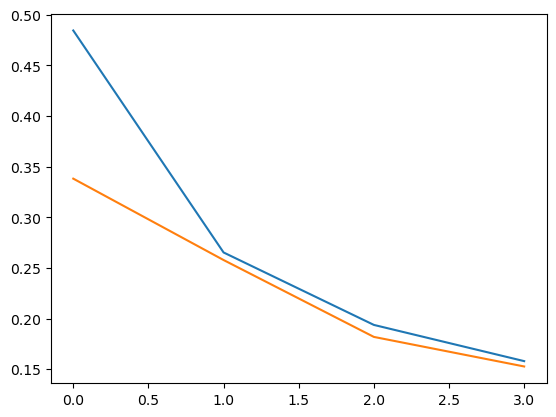

In [10]:
plt.plot(resnet50_model_history.history['loss'])
plt.plot(resnet50_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base_model.trainable = False

vgg16_model = Sequential()
vgg16_model.add(Input(shape=(224, 224, 3)))
vgg16_model.add(tf.keras.layers.Lambda(vgg16_preprocessing))
vgg16_model.add(vgg16_base_model)
vgg16_model.add(GlobalAveragePooling2D())
vgg16_model.add(Dense(1, activation="sigmoid"))

vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_model_history = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1217s 20s/step - accuracy: 0.6014 - f1: 0.6472 - loss: 0.6782 - pr_auc: 0.6255 - precision: 0.5912 - recall: 0.7150 - roc_auc: 0.6387 - val_accuracy: 0.6548 - val_f1: 0.6421 - val_loss: 0.6636 - val_pr_auc: 0.7410 - val_precision: 0.7048 - val_recall: 0.5896 - val_roc_auc: 0.7334
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1111s 19s/step - accuracy: 0.6703 - f1: 0.6865 - loss: 0.6438 - pr_auc: 0.7745 - precision: 0.6683 - recall: 0.7058 - roc_auc: 0.7653 - val_accuracy: 0.6297 - val_f1: 0.6366 - val_loss: 0.6370 - val_pr_auc: 0.8153 - val_precision: 0.6568 - val_recall: 0.6175 - val_roc_auc: 0.7731
Epoch 3/4
29/60 ━━━━━━━━━━━━━━━━━━━━ 13:22 26s/step - accuracy: 0.6570 - f1: 0.6691 - loss: 0.6269 - pr_auc: 0.8210 - precision: 0.6480 - recall: 0.6971 - roc_auc: 0.7931

In [ ]:
vgg16_model.save("../models/vgg16_model.keras")

File size: 56.22 MB


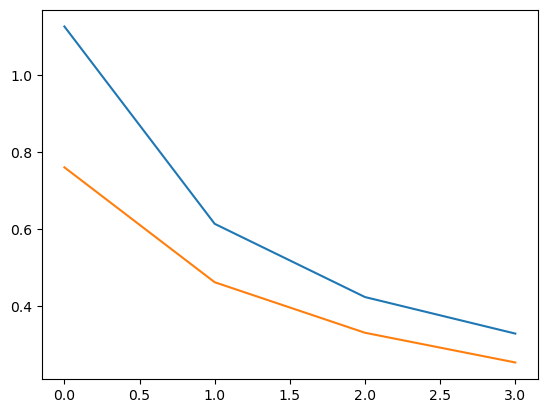

In [ ]:
plt.plot(vgg16_model_history.history['loss'])
plt.plot(vgg16_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

augmentation_model = Sequential([
    #tf.keras.layers.RandomRotation(0.02),
    #tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

vgg16_base_model.trainable = False

vgg16_aug_model = Sequential()
vgg16_aug_model.add(Input(shape=(224, 224, 3)))
vgg16_aug_model.add(augmentation_model)
vgg16_aug_model.add(tf.keras.layers.Lambda(vgg16_preprocessing))
vgg16_aug_model.add(vgg16_base_model)
vgg16_aug_model.add(GlobalAveragePooling2D())
vgg16_aug_model.add(Dense(1, activation="sigmoid"))

vgg16_aug_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_aug_model_history = vgg16_aug_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_aug_model_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
print(vgg16_aug_model_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1268s 21s/step - accuracy: 0.5538 - f1: 0.5810 - loss: 0.6906 - pr_auc: 0.5668 - precision: 0.5590 - recall: 0.6047 - roc_auc: 0.5634 - val_accuracy: 0.6569 - val_f1: 0.6952 - val_loss: 0.6676 - val_pr_auc: 0.7134 - val_precision: 0.6516 - val_recall: 0.7450 - val_roc_auc: 0.7115
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 892s 15s/step - accuracy: 0.6562 - f1: 0.6959 - loss: 0.6516 - pr_auc: 0.7735 - precision: 0.6354 - recall: 0.7692 - roc_auc: 0.7486 - val_accuracy: 0.6569 - val_f1: 0.6894 - val_loss: 0.6398 - val_pr_auc: 0.7961 - val_precision: 0.6570 - val_recall: 0.7251 - val_roc_auc: 0.7666
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 970s 16s/step - accuracy: 0.6724 - f1: 0.7041 - loss: 0.6244 - pr_auc: 0.7989 - precision: 0.6544 - recall: 0.7620 - roc_auc: 0.7773 - val_accuracy: 0.6904 - val_f1: 0.7448 - val_loss: 0.6175 - val_pr_auc: 0.8256 - val_precision: 0.6565 - val_recall: 0.8606 - val_roc_auc: 0.7918
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 966s 16s/s

In [ ]:
vgg16_aug_model.save("../models/vgg16_aug_model.keras")

In [ ]:
efficientnetb0_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnetb0_base_model.trainable = False

efficientnetb0_model = Sequential()
efficientnetb0_model.add(Input(shape=(224, 224, 3)))
efficientnetb0_model.add(efficientnetb0_base_model)
efficientnetb0_model.add(GlobalAveragePooling2D())
efficientnetb0_model.add(Dense(1, activation="sigmoid"))

efficientnetb0_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
efficientnetb0_model_history = efficientnetb0_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
print(efficientnetb0_results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 438s 7s/step - accuracy: 0.6661 - f1: 0.6918 - loss: 0.6136 - pr_auc: 0.7022 - precision: 0.6554 - recall: 0.7324 - roc_auc: 0.7316 - val_accuracy: 0.8347 - val_f1: 0.8597 - val_loss: 0.5104 - val_pr_auc: 0.8735 - val_precision: 0.7756 - val_recall: 0.9641 - val_roc_auc: 0.9047
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 352s 6s/step - accuracy: 0.8464 - f1: 0.8599 - loss: 0.4613 - pr_auc: 0.9126 - precision: 0.8061 - recall: 0.9213 - roc_auc: 0.9232 - val_accuracy: 0.8975 - val_f1: 0.9070 - val_loss: 0.4028 - val_pr_auc: 0.9654 - val_precision: 0.8659 - val_recall: 0.9522 - val_roc_auc: 0.9676
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.8887 - f1: 0.8972 - loss: 0.3808 - pr_auc: 0.9548 - precision: 0.8507 - recall: 0.9489 - roc_auc: 0.9570 - val_accuracy: 0.9079 - val_f1: 0.9179 - val_loss: 0.3394 - val_pr_auc: 0.9801 - val_precision: 0.8632 - val_recall: 0.9801 - val_roc_auc: 0.9791
E

In [ ]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")

File size: 16.27 MB


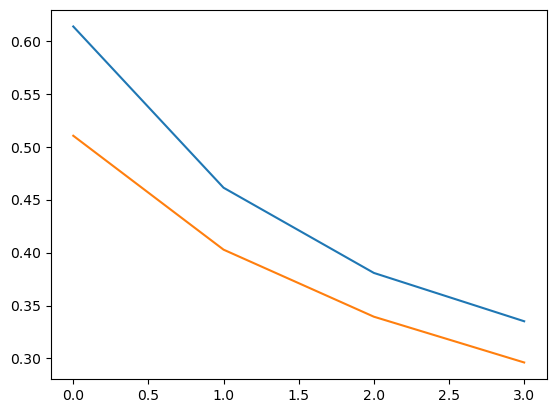

In [ ]:
plt.plot(efficientnetb0_model_history.history['loss'])
plt.plot(efficientnetb0_model_history.history['val_loss'])

plt.show()

In [11]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = False

mobilenetv2_model = Sequential()
mobilenetv2_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_model.add(tf.keras.layers.Lambda(mobilenetv2_preprocessing))
mobilenetv2_model.add(mobilenetv2_base_model)
mobilenetv2_model.add(GlobalAveragePooling2D())
mobilenetv2_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
mobilenetv2_model_history = mobilenetv2_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.6855 - f1: 0.7011 - loss: 0.5792 - pr_auc: 0.7572 - precision: 0.6821 - recall: 0.7211 - roc_auc: 0.7602 - val_accuracy: 0.8264 - val_f1: 0.8369 - val_loss: 0.4552 - val_pr_auc: 0.9227 - val_precision: 0.8256 - val_recall: 0.8486 - val_roc_auc: 0.9149
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.8537 - f1: 0.8611 - loss: 0.3916 - pr_auc: 0.9404 - precision: 0.8370 - recall: 0.8866 - roc_auc: 0.9402 - val_accuracy: 0.8787 - val_f1: 0.8926 - val_loss: 0.3588 - val_pr_auc: 0.9615 - val_precision: 0.8339 - val_recall: 0.9602 - val_roc_auc: 0.9581
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.8945 - f1: 0.8995 - loss: 0.3135 - pr_auc: 0.9669 - precision: 0.8768 - recall: 0.9234 - roc_auc: 0.9668 - val_accuracy: 0.8933 - val_f1: 0.9047 - val_loss: 0.3011 - val_pr_auc: 0.9754 - val_precision: 0.8521 - val_recall: 0.9641 - val_roc_auc: 0.9729
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - acc

In [12]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")

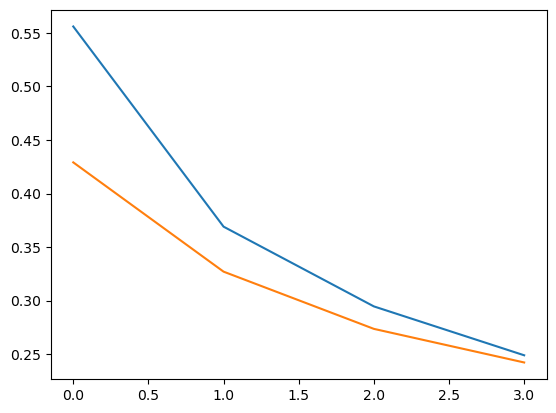

In [5]:
plt.plot(mobilenetv2_model_history.history['loss'])
plt.plot(mobilenetv2_model_history.history['val_loss'])

plt.show()

In [4]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = True


for layer in mobilenetv2_base_model.layers[:-20]:
    layer.trainable = False


mobilenetv2_tuned_model = Sequential()
mobilenetv2_tuned_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_tuned_model.add(tf.keras.layers.Lambda(mobilenetv2_preprocessing))
mobilenetv2_tuned_model.add(mobilenetv2_base_model)
mobilenetv2_tuned_model.add(GlobalAveragePooling2D())
mobilenetv2_tuned_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_tuned_model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min",
                                        patience=3,
                                        restore_best_weights=True)


mobilenetv2_tuned_model_history = mobilenetv2_tuned_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks = [earlystopping]

)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.6917 - f1: 0.7258 - loss: 0.5749 - pr_auc: 0.7914 - precision: 0.6658 - recall: 0.7978 - roc_auc: 0.7840 - val_accuracy: 0.7238 - val_f1: 0.7643 - val_loss: 0.5594 - val_pr_auc: 0.8450 - val_precision: 0.6926 - val_recall: 0.8526 - val_roc_auc: 0.8250
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.9039 - f1: 0.9103 - loss: 0.3761 - pr_auc: 0.9628 - precision: 0.8705 - recall: 0.9540 - roc_auc: 0.9632 - val_accuracy: 0.8117 - val_f1: 0.8358 - val_loss: 0.4667 - val_pr_auc: 0.9285 - val_precision: 0.7710 - val_recall: 0.9124 - val_roc_auc: 0.9129
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 197s 3s/step - accuracy: 0.9404 - f1: 0.9434 - loss: 0.2759 - pr_auc: 0.9863 - precision: 0.9179 - recall: 0.9704 - roc_auc: 0.9860 - val_accuracy: 0.8494 - val_f1: 0.8672 - val_loss: 0.3952 - val_pr_auc: 0.9577 - val_precision: 0.8076 - val_recall: 0.9363 - val_roc_auc: 0.9483
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - 

In [5]:
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_tuned_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.9062 - f1: 0.9146 - loss: 0.2836 - pr_auc: 0.9789 - precision: 0.8596 - recall: 0.9772 - roc_auc: 0.9786    
{'accuracy': 0.9061976671218872, 'f1': 0.914634108543396, 'loss': 0.283600777387619, 'pr_auc': 0.9788667559623718, 'precision': 0.8595988750457764, 'recall': 0.9771987199783325, 'roc_auc': 0.978597104549408}


In [6]:
mobilenetv2_tuned_model.save("../models/mobilenetv2_tuned_model.keras")

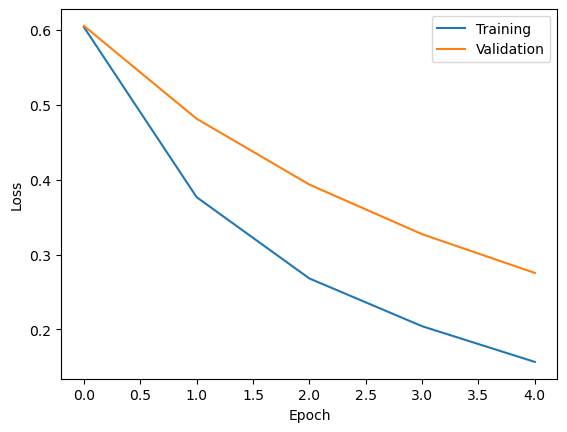

In [46]:
plt.plot(mobilenetv2_tuned_model_history.history['loss'], label="Training")
plt.plot(mobilenetv2_tuned_model_history.history['val_loss'], label ="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.show()

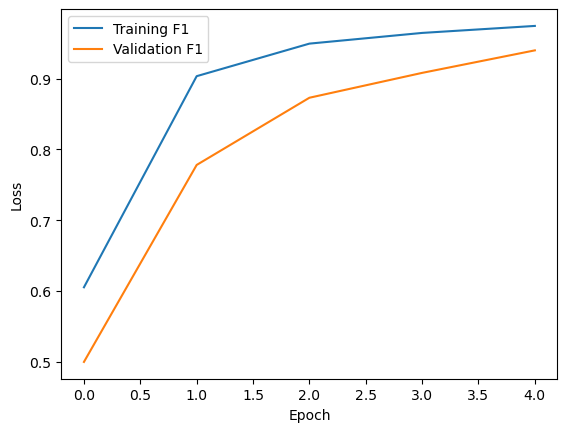

In [45]:
plt.plot(mobilenetv2_tuned_model_history.history["f1"], label="Training F1")
plt.plot(mobilenetv2_tuned_model_history.history["val_f1"], label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [4]:
baseline_model = load_model("../models/custom_model.keras")
custom_model_results = baseline_model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)
path = Path("../models/custom_model.keras")
custom_model_file_size = round(path.stat().st_size / (1024**2),2)
custom_model_params = baseline_model.count_params()

resnet50_model = load_model("../models/resnet50_model.keras", custom_objects={"preprocess_input": resnet50_preprocessing})
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/resnet50_model.keras")
resnet50_file_size = round(path.stat().st_size / (1024**2),2)
resnet50_params = resnet50_model.count_params()

vgg16_model = load_model("../models/vgg16_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_model.keras")
vgg16_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_params = vgg16_model.count_params()

vgg16_aug_model = load_model("../models/vgg16_aug_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
vgg16_aug_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_aug_model.keras")
vgg16_aug_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_aug_params = vgg16_aug_model.count_params()

efficientnetb0_model = load_model("../models/efficientnetb0_model.keras")
efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/efficientnetb0_model.keras")
efficientnetb0_file_size = round(path.stat().st_size / (1024**2),2)
efficientnetb0_params = efficientnetb0_model.count_params()

mobilenetv2_model = load_model("../models/mobilenetv2_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_model.keras")
mobilenetv2_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_params = mobilenetv2_model.count_params()

mobilenetv2_tuned_model = load_model("../models/mobilenetv2_tuned_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_tuned_model.keras")
mobilenetv2_tuned_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_tuned_params = mobilenetv2_tuned_model.count_params()



19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 474ms/step - accuracy: 0.8777 - f1: 0.8937 - loss: 0.3277 - pr_auc: 0.9902 - precision: 0.8079 - recall: 1.0000 - roc_auc: 0.9948         
{'accuracy': 0.8777219653129578, 'f1': 0.8937408924102783, 'loss': 0.32771024107933044, 'pr_auc': 0.9902495741844177, 'precision': 0.807894766330719, 'recall': 1.0, 'roc_auc': 0.9947826862335205}

19/19 ━━━━━━━━━━━━━━━━━━━━ 128s 6s/step - accuracy: 0.4858 - f1: 0.0000e+00 - loss: 6.9083 - pr_auc: 0.5142 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.5000
19/19 ━━━━━━━━━━━━━━━━━━━━ 274s 14s/step - accuracy: 0.8660 - f1: 0.8662 - loss: 0.3194 - pr_auc: 0.9410 - precision: 0.8900 - recall: 0.8436 - roc_auc: 0.9429      
19/19 ━━━━━━━━━━━━━━━━━━━━ 252s 13s/step - accuracy: 0.6767 - f1: 0.6497 - loss: 1.2232 - pr_auc: 0.7630 - precision: 0.7336 - recall: 0.5831 - roc_auc: 0.7751      
19/19 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.9162 - f1: 0.9216 - loss: 0.3060 - pr_auc: 0.9797 - precision: 0.8882 - recal

In [3]:
mobilenetv2_tuned_model = load_model("../models/mobilenetv2_tuned_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)


19/19 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.8660 - f1: 0.8529 - loss: 0.3341 - pr_auc: 0.9822 - precision: 0.9789 - recall: 0.7557 - roc_auc: 0.9814  


In [14]:
comparsion_table = pd.DataFrame({
    "Model": ["Custom_Model", "ResNet50", "VGG16", "VGG16_Aug", "EfficientnetB0", "MobilenetV2", "MobilenetV2_tuned"],
    "Accuracy": [custom_model_results["accuracy"], resnet50_results["accuracy"], vgg16_results["accuracy"], vgg16_aug_results["accuracy"], efficientnetb0_results["accuracy"], mobilenetv2_results["accuracy"], mobilenetv2_tuned_results["accuracy"]],
    "F1": [custom_model_results["f1"], resnet50_results["f1"], vgg16_results["f1"], vgg16_aug_results["f1"], efficientnetb0_results["f1"], mobilenetv2_results["f1"], mobilenetv2_tuned_results["f1"]],
    "Recall": [custom_model_results["recall"], resnet50_results["recall"], vgg16_results["recall"], vgg16_aug_results["recall"], efficientnetb0_results["recall"], mobilenetv2_results["recall"], mobilenetv2_tuned_results["recall"]],
    "Precision": [custom_model_results["precision"], resnet50_results["precision"], vgg16_results["precision"], vgg16_aug_results["precision"], efficientnetb0_results["precision"], mobilenetv2_results["precision"], mobilenetv2_tuned_results["precision"]],
    "ROC_AUC": [custom_model_results["roc_auc"], resnet50_results["roc_auc"], vgg16_results["roc_auc"], vgg16_aug_results["roc_auc"], efficientnetb0_results["roc_auc"], mobilenetv2_results["roc_auc"], mobilenetv2_tuned_results["roc_auc"]],
    "PR_AUC": [custom_model_results["pr_auc"], resnet50_results["pr_auc"], vgg16_results["pr_auc"], vgg16_aug_results["pr_auc"], efficientnetb0_results["pr_auc"], mobilenetv2_results["pr_auc"], mobilenetv2_tuned_results["pr_auc"]],
    "File_Size_MB": [custom_model_file_size, resnet50_file_size, vgg16_file_size, vgg16_aug_file_size, efficientnetb0_file_size, mobilenetv2_file_size, mobilenetv2_tuned_file_size],
    "Parameters": [custom_model_params, resnet50_params, vgg16_params, vgg16_aug_params, efficientnetb0_params, mobilenetv2_params, mobilenetv2_tuned_params]
})

In [15]:
comparsion_table.to_csv("../data/comparsion.csv")

In [16]:
comparsion_table

,Model,Accuracy,F1,Recall,Precision,ROC_AUC,PR_AUC,File_Size_MB,Parameters
0,Custom_Model,0.877722,0.893741,1.000000,0.807895,0.994783,0.990250,0.89,73825
1,ResNet50,0.971524,0.972887,0.993485,0.953125,0.997265,0.997342,90.63,23589761
2,VGG16,0.865997,0.866221,0.843648,0.890034,0.942912,0.940999,56.22,14715201
3,VGG16_Aug,0.676717,0.649728,0.583062,0.733607,0.775076,0.763047,56.23,14715201
4,EfficientnetB0,0.916248,0.921630,0.957655,0.888218,0.977991,0.979725,16.27,4050852
5,MobilenetV2,0.926298,0.927631,0.918567,0.936877,0.983124,0.984609,9.19,2259265
6,MobilenetV2_tuned,0.946399,0.947712,0.944625,0.950820,0.988504,0.988714,18.40,2259265


In [ ]:
# Your trained model
model = mobilenetv2_tuned_model

img_size = (224, 224)

# Use the same preprocessing already included in your model.
# Do not preprocess the image again outside the model.

# Last convolutional layer in MobileNetV2
last_conv_layer_name = "Conv_1"

# Path to one of your test images

img_path = random.choice(glob.glob("../data/testing/flip/*.jpg"))


In [56]:
def get_img_array(img_path, size=(224, 224)):
    # Load and resize the image to 224 × 224
    img = keras.utils.load_img(img_path, target_size=size)

    # Convert to a float32 array: (224, 224, 3)
    array = keras.utils.img_to_array(img)

    # Add the batch dimension: (1, 224, 224, 3)
    array = np.expand_dims(array, axis=0)

    return array

In [57]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="out_relu",
                         pred_index=None):

    # Find the MobileNetV2 base inside your Sequential model
    base_model = next(
        layer for layer in model.layers
        if isinstance(layer, keras.Model)
    )

    grad_model = keras.models.Model(
        base_model.inputs,
        [
            base_model.get_layer(last_conv_layer_name).output,
            base_model.output
        ]
    )

    x = tf.convert_to_tensor(img_array, dtype=tf.float32)
    base_index = model.layers.index(base_model)

    # Apply preprocessing layers before the base model
    for layer in model.layers[:base_index]:
        x = layer(x, training=False)

    with tf.GradientTape() as tape:
        tape.watch(x)

        conv_output, x = grad_model(x, training=False)

        # Apply pooling and classification layers
        for layer in model.layers[base_index + 1:]:
            x = layer(x, training=False)

        # Select the predicted class unless one is specified
        if pred_index is None:
            pred_index = int(x[0, 0] >= 0.5)

        class_score = x[:, 0] if pred_index == 1 else 1 - x[:, 0]

    # Calculate feature-map importance
    grads = tape.gradient(class_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combine feature maps into a heatmap
    heatmap = tf.reduce_sum(conv_output[0] * pooled_grads, axis=-1)

    # Normalize between 0 and 1
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    return heatmap.numpy()

In [53]:
def make_gradcam_heatmap(img_array, model):
    # Find MobileNetV2 inside your model
    base_model = model.get_layer("mobilenetv2_1.00_224")
    base_index = model.layers.index(base_model)

    x = tf.convert_to_tensor(img_array, dtype=tf.float32)

    # Apply preprocessing
    for layer in model.layers[:base_index]:
        x = layer(x, training=False)

    # Get MobileNetV2's feature maps
    features = base_model(x, training=False)

    with tf.GradientTape() as tape:
        tape.watch(features)
        prediction = features

        # Apply pooling and the final Dense layer
        for layer in model.layers[base_index + 1:]:
            prediction = layer(prediction, training=False)

        # Explain the predicted class
        probability = prediction[0, 0]
        score = tf.where(probability >= 0.5, probability, 1 - probability)

    # Calculate the importance of each feature map
    gradients = tape.gradient(score, features)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    # Combine and normalize
    heatmap = tf.reduce_sum(features[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    return heatmap.numpy()

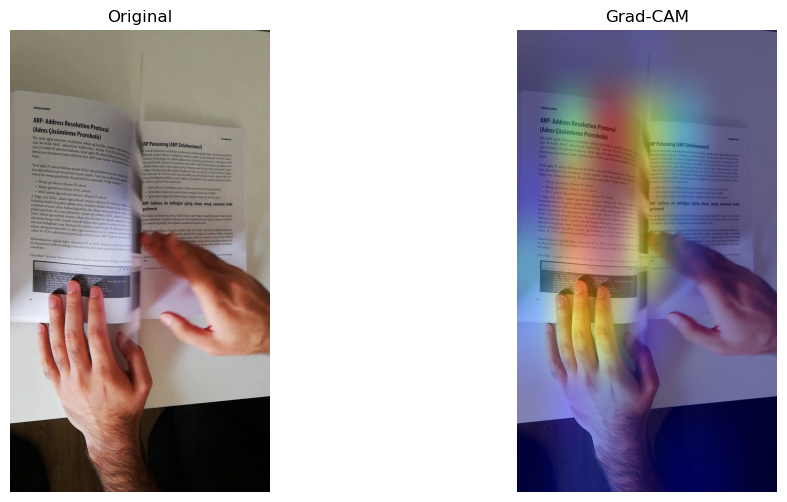

In [58]:

def save_and_display_gradcam(img_path, heatmap,
                             cam_path="../reports/cam.jpg", alpha=0.4):
    # Load the original image
    original = keras.utils.load_img(img_path)
    img = keras.utils.img_to_array(original)

    # Convert the heatmap to RGB colours
    heatmap = np.uint8(255 * np.clip(heatmap, 0, 1))
    colored_heatmap = plt.get_cmap("jet")(heatmap)[..., :3]
    colored_heatmap = np.uint8(255 * colored_heatmap)

    # Resize the heatmap to match the original image
    colored_heatmap = keras.utils.array_to_img(
        colored_heatmap, scale=False
    )
    colored_heatmap = colored_heatmap.resize(
        (img.shape[1], img.shape[0])
    )
    colored_heatmap = keras.utils.img_to_array(colored_heatmap)

    # Blend the heatmap with the original image
    overlay = (1 - alpha) * img + alpha * colored_heatmap
    overlay = keras.utils.array_to_img(overlay, scale=False)

    # Save the overlay
    Path(cam_path).parent.mkdir(parents=True, exist_ok=True)
    overlay.save(cam_path)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img.astype("uint8"))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.show()
save_and_display_gradcam(img_path, heatmap)